# IBM Quantum — Temporal Sweet-Spot Experiment
## Recent training windows + RF/XGBoost LOBO + prospective Sep-4 / Sep-5 / Sep-6 rankings

This notebook follows the **same evaluation workflow as the established Model B / Model C notebook**, with one controlled change: the historical training-window length.

### Temporal windows
- 1 observed calibration date
- 3 observed calibration dates
- 7 observed calibration dates
- 30 observed calibration dates

### Evaluation
For **each temporal window**, both algorithms are evaluated with **Leave-One-Backend-Out (LOBO)**:

- train on FEZ + Kingston → test Marrakesh
- train on FEZ + Marrakesh → test Kingston
- train on Kingston + Marrakesh → test FEZ

Metrics are recorded for every held-out backend:
- ROC-AUC
- Accuracy
- Balanced Accuracy
- F1
- MCC

The algorithm with the highest **mean LOBO AUC** is selected independently for each temporal window.

### Prospective prediction
After LOBO evaluation, the selected algorithm for each window is retrained for the requested prediction dates:
- Sep 4, 2026
- Sep 5, 2026
- Sep 6, 2026

The notebook saves **only four final `.pkl` models** — one per temporal window, trained through Sep 5 for the Sep-6 hardware-selection stage. Sep-4 and Sep-5 ranking models are trained in memory and their predictions are saved as CSVs.

**Data source:** Railway MySQL `calibration_history` through the project's existing `database.py`.

**No IBM Quantum hardware jobs are submitted here.**


## 1. Imports, project paths, and experiment configuration

This uses the existing `database.py` connection instead of any backup CSV.

The output is isolated under:
- `results/temporal_sweet_spot/`
- `results/temporal_sweet_spot/figures/`
- `models/temporal_sweet_spot/`

Existing Model A/B/C artifacts are not overwritten.


In [1]:
from pathlib import Path
from datetime import date
import sys
import os
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    accuracy_score,
    roc_curve,
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ------------------------------------------------------------
# PROJECT ROOT
# ------------------------------------------------------------
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "database.py").exists() and (PROJECT_ROOT.parent / "database.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "database.py").exists():
    raise FileNotFoundError(
        "database.py not found. Run this notebook from the project root "
        "or the notebooks/ directory, or set PROJECT_ROOT manually."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import database

# ------------------------------------------------------------
# OUTPUTS
# ------------------------------------------------------------
RESULTS_DIR = PROJECT_ROOT / "results" / "temporal_sweet_spot"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models" / "temporal_sweet_spot"

for d in [RESULTS_DIR, FIGURES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# EXPERIMENT
# ------------------------------------------------------------
WINDOWS = {
    "1day": 1,
    "3day": 3,
    "7day": 7,
    "30day": 30,
}

PREDICTION_DATES = [
    pd.Timestamp("2026-09-04").date(),
    pd.Timestamp("2026-09-05").date(),
    pd.Timestamp("2026-09-06").date(),
]

T1_THRESH = 100.0
T2_THRESH = 50.0
RE_THRESH = 0.05

HIST_FEATURES = [
    "hist_T1_mean", "hist_T1_std", "hist_T1_min", "hist_T1_max",
    "hist_T2_mean", "hist_T2_std", "hist_T2_min", "hist_T2_max",
    "hist_RE_mean", "hist_RE_std", "hist_RE_min", "hist_RE_max",
    "prev_T1", "prev_T2", "prev_RE",
    "hist_coherence_product", "hist_t2_t1_ratio",
]

XGB_PARAMS = dict(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    verbosity=0,
)

RF_PARAMS = dict(
    n_estimators=200,
    max_depth=8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

BACKEND_EXPECTED = {
    "ibm_fez",
    "ibm_kingston",
    "ibm_marrakesh",
}

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Prediction dates:", PREDICTION_DATES)
print("Temporal windows:", WINDOWS)
print("Features:", len(HIST_FEATURES))


PROJECT_ROOT: D:\Downloads\uday projects\ibm_quantum
Prediction dates: [datetime.date(2026, 9, 4), datetime.date(2026, 9, 5), datetime.date(2026, 9, 6)]
Temporal windows: {'1day': 1, '3day': 3, '7day': 7, '30day': 30}
Features: 17


## 2. Load the complete calibration history from Railway MySQL

The source of truth is the live `calibration_history` table.

The notebook intentionally does **not** read:
- `backup_calibration_history_*.csv`
- `ibm_data.csv`
- any other local calibration CSV

This is the same raw schema used by the project's database layer.


In [2]:
# ============================================================
# RAILWAY MYSQL -> calibration_history
# ============================================================

conn = database.get_connection()

try:
    raw = pd.read_sql(
        """
        SELECT
            backend,
            qubit,
            snapshot_date,
            T1_us,
            T2_us,
            readout_error
        FROM calibration_history
        ORDER BY backend, qubit, snapshot_date
        """,
        conn,
    )
finally:
    conn.close()

required = [
    "snapshot_date", "backend", "qubit",
    "T1_us", "T2_us", "readout_error"
]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing required database columns: {missing}")

raw["snapshot_date"] = pd.to_datetime(raw["snapshot_date"], errors="coerce")
for c in ["qubit", "T1_us", "T2_us", "readout_error"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

raw = raw.dropna(subset=required).copy()
raw["qubit"] = raw["qubit"].astype(int)

raw = (
    raw.sort_values(["backend", "qubit", "snapshot_date"])
       .drop_duplicates(["backend", "qubit", "snapshot_date"], keep="last")
       .reset_index(drop=True)
)

print("=" * 70)
print("RAW RAILWAY MYSQL DATA")
print("=" * 70)
print("Rows:", f"{len(raw):,}")
print("Date range:", raw.snapshot_date.min().date(), "→", raw.snapshot_date.max().date())
print("Observed dates:", raw.snapshot_date.dt.date.nunique())
print("Backends:", sorted(raw.backend.unique()))

assert raw.T1_us.mean() < 10000, "T1 unit sanity check failed."

if not BACKEND_EXPECTED.issubset(set(raw.backend.unique())):
    raise ValueError(
        f"Expected all three IBM backends {sorted(BACKEND_EXPECTED)}. "
        f"Found {sorted(raw.backend.unique())}."
    )

display(
    raw.groupby("backend")
       .agg(
           rows=("qubit", "size"),
           qubits=("qubit", "nunique"),
           dates=("snapshot_date", lambda s: s.dt.date.nunique()),
           first_date=("snapshot_date", "min"),
           last_date=("snapshot_date", "max"),
       )
       .reset_index()
)


RAW RAILWAY MYSQL DATA
Rows: 26,562
Date range: 2026-07-13 → 2026-09-07
Observed dates: 57
Backends: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']


,backend,rows,qubits,dates,first_date,last_date
0,ibm_fez,8835,155,57,2026-07-13,2026-09-07
1,ibm_kingston,8835,155,57,2026-07-13,2026-09-07
2,ibm_marrakesh,8892,156,57,2026-07-13,2026-09-07


## 3. Label + leakage-safe historical features

This reproduces the established 17-feature construction:

- viability label: `T1 > 100 µs`, `T2 > 50 µs`, `readout_error < 0.05`
- historical statistics use `shift(1)` before `expanding()`
- `prev_*` is the immediately previous calibration
- coherence product and T2/T1 ratio use historical means

The current date's T1/T2/readout error therefore cannot enter its own feature vector.


In [3]:
# ============================================================
# LABEL + HISTORICAL FEATURES
# ============================================================

def add_label(df):
    out = df.copy()
    out["label"] = (
        (out["T1_us"] > T1_THRESH)
        & (out["T2_us"] > T2_THRESH)
        & (out["readout_error"] < RE_THRESH)
    ).astype(int)
    return out


def add_hist_features(df):
    out = df.sort_values(
        ["backend", "qubit", "snapshot_date"]
    ).copy()

    out["snapshot_id"] = (
        out.groupby(["backend", "qubit"])["snapshot_date"]
           .transform(lambda x: pd.factorize(x)[0])
    )

    for col, alias in [
        ("T1_us", "T1"),
        ("T2_us", "T2"),
        ("readout_error", "RE"),
    ]:
        g = out.groupby(["backend", "qubit"])[col]

        out[f"hist_{alias}_mean"] = g.transform(
            lambda x: x.shift(1).expanding().mean()
        )
        out[f"hist_{alias}_std"] = g.transform(
            lambda x: x.shift(1).expanding().std()
        )
        out[f"hist_{alias}_min"] = g.transform(
            lambda x: x.shift(1).expanding().min()
        )
        out[f"hist_{alias}_max"] = g.transform(
            lambda x: x.shift(1).expanding().max()
        )
        out[f"prev_{alias}"] = g.transform(
            lambda x: x.shift(1)
        )

    out["hist_coherence_product"] = (
        out["hist_T1_mean"] * out["hist_T2_mean"]
    )
    out["hist_t2_t1_ratio"] = (
        out["hist_T2_mean"] / (out["hist_T1_mean"] + 1e-9)
    )

    return out


featured = add_hist_features(add_label(raw))

# Exact leakage audit used by the previous training workflow.
snap0 = featured[featured["snapshot_id"] == 0]
nan_rates = snap0[HIST_FEATURES].isna().mean()

print("Snapshot-0 feature NaN rates:")
display(nan_rates.to_frame("NaN_rate"))

assert (nan_rates == 1.0).all(), "LEAKAGE AUDIT FAILED."
print("LEAKAGE AUDIT PASSED: first observation of every qubit has no historical features.")


Snapshot-0 feature NaN rates:


,NaN_rate
hist_T1_mean,1.0
hist_T1_std,1.0
hist_T1_min,1.0
hist_T1_max,1.0
hist_T2_mean,1.0
hist_T2_std,1.0
hist_T2_min,1.0
hist_T2_max,1.0
hist_RE_mean,1.0
hist_RE_std,1.0


LEAKAGE AUDIT PASSED: first observation of every qubit has no historical features.


## 4. Define temporal training windows

For a cutoff date, a window means the **N latest observed calibration dates strictly before the cutoff**.

This uses observed dates rather than assuming that every calendar date has a snapshot.

For LOBO, the same temporal window is selected first, then the held-out backend is removed from training.

For prospective prediction, the training cutoff is the prediction date, so:
- Sep-4 model uses history before Sep-4
- Sep-5 model uses history before Sep-5
- Sep-6 model uses history before Sep-6


In [4]:
# ============================================================
# TEMPORAL WINDOW HELPERS
# ============================================================

def observed_dates_before(df, cutoff_date):
    cutoff = pd.Timestamp(cutoff_date)
    dates = (
        df.loc[df["snapshot_date"] < cutoff, "snapshot_date"]
          .dt.date
          .drop_duplicates()
          .sort_values()
          .tolist()
    )
    return dates


def select_window(df, cutoff_date, window_days):
    dates = observed_dates_before(df, cutoff_date)

    if len(dates) < window_days:
        raise ValueError(
            f"Only {len(dates)} observed dates exist before {cutoff_date}; "
            f"cannot construct {window_days}-date window."
        )

    selected_dates = dates[-window_days:]

    out = df[
        df["snapshot_date"].dt.date.isin(selected_dates)
    ].copy()

    out = out.dropna(subset=HIST_FEATURES + ["label"]).copy()

    return out, selected_dates


def prediction_rows(df, prediction_date):
    out = df[
        df["snapshot_date"].dt.date == prediction_date
    ].copy()

    # Critical: prediction rows require historical features,
    # but their current raw calibration values are not model inputs.
    out = out.dropna(subset=HIST_FEATURES).copy()

    if out.empty:
        raise ValueError(
            f"No complete historical feature rows available for {prediction_date}."
        )

    return out


## 5. LOBO evaluation — exactly the established workflow

For every window and every algorithm:

```text
FEZ + Kingston       → test Marrakesh
FEZ + Marrakesh      → test Kingston
Kingston + Marrakesh → test FEZ
```

The held-out backend is never included in that fold's training data.

The algorithm selection rule is exactly the established one:

> **Select the algorithm with the highest mean LOBO ROC-AUC.**

We retain every backend-level result, not just the mean.


In [5]:
# ============================================================
# LOBO
# ============================================================

def run_lobo(data, model_class, params, model_name):
    rows = []
    preds = {}

    backends = sorted(data["backend"].unique())

    if len(backends) != 3:
        raise ValueError(
            f"LOBO requires exactly 3 backends in each window. Found: {backends}"
        )

    for test_backend in backends:
        train = data[data["backend"] != test_backend].copy()
        test = data[data["backend"] == test_backend].copy()

        if train["label"].nunique() < 2:
            raise ValueError(
                f"{model_name}, held-out={test_backend}: training fold has one class."
            )

        if test["label"].nunique() < 2:
            raise ValueError(
                f"{model_name}, held-out={test_backend}: test fold has one class."
            )

        model = model_class(**params)
        model.fit(train[HIST_FEATURES], train["label"])

        y_true = test["label"].to_numpy()
        y_prob = model.predict_proba(test[HIST_FEATURES])[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)

        rows.append({
            "Model": model_name,
            "Test_Backend": test_backend,
            "Train_Rows": len(train),
            "Test_Rows": len(test),
            "AUC": roc_auc_score(y_true, y_prob),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "MCC": matthews_corrcoef(y_true, y_pred),
        })

        preds[test_backend] = {
            "y_true": y_true,
            "y_prob": y_prob,
            "y_pred": y_pred,
            "qubit": test["qubit"].to_numpy(),
        }

    return pd.DataFrame(rows), preds


def evaluate_window(data, window_label):
    xgb_results, xgb_preds = run_lobo(
        data, XGBClassifier, XGB_PARAMS, "XGBoost"
    )
    rf_results, rf_preds = run_lobo(
        data, RandomForestClassifier, RF_PARAMS, "RandomForest"
    )

    if xgb_results["AUC"].mean() >= rf_results["AUC"].mean():
        best_name = "XGBoost"
        best_results = xgb_results
        best_predictions = xgb_preds
    else:
        best_name = "RandomForest"
        best_results = rf_results
        best_predictions = rf_preds

    print("\n" + "=" * 75)
    print(window_label, "— XGBoost")
    print("=" * 75)
    display(xgb_results.round(4))
    print(
        f"Mean LOBO AUC: {xgb_results.AUC.mean():.4f} | "
        f"Min LOBO AUC: {xgb_results.AUC.min():.4f}"
    )

    print("\n" + "=" * 75)
    print(window_label, "— Random Forest")
    print("=" * 75)
    display(rf_results.round(4))
    print(
        f"Mean LOBO AUC: {rf_results.AUC.mean():.4f} | "
        f"Min LOBO AUC: {rf_results.AUC.min():.4f}"
    )

    print(
        f"\nBEST ALGORITHM: {best_name} "
        f"(highest mean LOBO AUC)"
    )

    return {
        "window_label": window_label,
        "best_name": best_name,
        "best_results": best_results,
        "best_predictions": best_predictions,
        "xgb_results": xgb_results,
        "rf_results": rf_results,
        "all_results": pd.concat(
            [xgb_results, rf_results],
            ignore_index=True
        ),
    }


## 6. Run LOBO for 1 / 3 / 7 / 30 observed-date windows

The cutoff is **Sep-4, 2026**, because Sep-4 is the first prospective prediction date.

Thus the LOBO comparison is performed on the same historical period immediately preceding the prospective experiment. This makes the temporal-window comparison controlled and relevant to the Sep-4→Sep-6 hardware validation.


In [6]:
# ============================================================
# TEMPORAL LOBO SWEEP
# ============================================================

LOBO_CUTOFF = pd.Timestamp("2026-09-04").date()

lobo_results = {}
window_data = {}
window_dates = {}

for window_label, window_days in WINDOWS.items():
    data, dates_used = select_window(
        featured,
        LOBO_CUTOFF,
        window_days,
    )

    print("\n" + "#" * 80)
    print(
        f"WINDOW: {window_label} | "
        f"{dates_used[0]} → {dates_used[-1]} | "
        f"{len(dates_used)} observed dates"
    )
    print("#" * 80)

    print("Rows:", f"{len(data):,}")
    print("Viable rate:", f"{data.label.mean():.4f}")
    print("Rows by backend:")
    display(
        data.groupby("backend")
            .agg(
                rows=("qubit", "size"),
                viable_rate=("label", "mean"),
            )
            .reset_index()
    )

    window_data[window_label] = data
    window_dates[window_label] = dates_used
    lobo_results[window_label] = evaluate_window(
        data,
        f"TEMPORAL WINDOW — {window_label}"
    )



################################################################################
WINDOW: 1day | 2026-09-03 → 2026-09-03 | 1 observed dates
################################################################################
Rows: 466
Viable rate: 0.6202
Rows by backend:


,backend,rows,viable_rate
0,ibm_fez,155,0.548387
1,ibm_kingston,155,0.780645
2,ibm_marrakesh,156,0.532051



TEMPORAL WINDOW — 1day — XGBoost


,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,XGBoost,ibm_fez,311,155,0.8714,0.8129,0.8080,0.8343,0.6212
1,XGBoost,ibm_kingston,311,155,0.8867,0.8903,0.8134,0.9312,0.6652
2,XGBoost,ibm_marrakesh,310,156,0.8990,0.8141,0.8104,0.8324,0.6271


Mean LOBO AUC: 0.8857 | Min LOBO AUC: 0.8714

TEMPORAL WINDOW — 1day — Random Forest


,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,RandomForest,ibm_fez,311,155,0.8706,0.7806,0.7748,0.8068,0.5555
1,RandomForest,ibm_kingston,311,155,0.9064,0.8839,0.7882,0.9280,0.6383
2,RandomForest,ibm_marrakesh,310,156,0.8983,0.8205,0.8123,0.8478,0.6524


... (15 outputs left out)

,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,XGBoost,ibm_fez,9330,4650,0.8625,0.7856,0.7792,0.8160,0.5808
1,XGBoost,ibm_kingston,9330,4650,0.9177,0.9133,0.8600,0.9448,0.7442
2,XGBoost,ibm_marrakesh,9300,4680,0.8796,0.7880,0.7856,0.8162,0.5965


Mean LOBO AUC: 0.8866 | Min LOBO AUC: 0.8625

TEMPORAL WINDOW — 30day — Random Forest


,Model,Test_Backend,Train_Rows,Test_Rows,AUC,Accuracy,Balanced_Accuracy,F1,MCC
0,RandomForest,ibm_fez,9330,4650,0.8669,0.7796,0.7717,0.8153,0.5761
1,RandomForest,ibm_kingston,9330,4650,0.9301,0.9228,0.8599,0.9514,0.7693
2,RandomForest,ibm_marrakesh,9300,4680,0.8869,0.7900,0.7872,0.8205,0.6069


Mean LOBO AUC: 0.8946 | Min LOBO AUC: 0.8669

BEST ALGORITHM: RandomForest (highest mean LOBO AUC)


## 7. Save complete LOBO results + temporal comparison

This preserves the full backend-by-backend results so the experiment is auditable.

The main comparison is the **mean LOBO AUC** across the three held-out backends.


In [7]:
# ============================================================
# SAVE LOBO RESULTS
# ============================================================

all_lobo = []

for window_label, result in lobo_results.items():
    x = result["all_results"].copy()
    x.insert(0, "Window", window_label)
    x["Window_Dates"] = (
        f"{window_dates[window_label][0]} → "
        f"{window_dates[window_label][-1]}"
    )
    all_lobo.append(x)

all_lobo_df = pd.concat(all_lobo, ignore_index=True)

all_lobo_path = RESULTS_DIR / "temporal_sweet_spot_lobo_all_results.csv"
all_lobo_df.to_csv(all_lobo_path, index=False)

comparison_rows = []

for window_label, result in lobo_results.items():
    for algorithm, result_df in [
        ("XGBoost", result["xgb_results"]),
        ("RandomForest", result["rf_results"]),
    ]:
        comparison_rows.append({
            "Window": window_label,
            "Window_Dates": (
                f"{window_dates[window_label][0]} → "
                f"{window_dates[window_label][-1]}"
            ),
            "Algorithm": algorithm,
            "Mean_LOBO_AUC": result_df["AUC"].mean(),
            "Min_LOBO_AUC": result_df["AUC"].min(),
            "Mean_Accuracy": result_df["Accuracy"].mean(),
            "Mean_Balanced_Accuracy": result_df["Balanced_Accuracy"].mean(),
            "Mean_F1": result_df["F1"].mean(),
            "Mean_MCC": result_df["MCC"].mean(),
        })

comparison = pd.DataFrame(comparison_rows)

best_summary = []
for window_label, result in lobo_results.items():
    r = result["best_results"]
    best_summary.append({
        "Window": window_label,
        "Window_Dates": (
            f"{window_dates[window_label][0]} → "
            f"{window_dates[window_label][-1]}"
        ),
        "Selected_Algorithm": result["best_name"],
        "Mean_LOBO_AUC": r["AUC"].mean(),
        "Min_LOBO_AUC": r["AUC"].min(),
        "Mean_Accuracy": r["Accuracy"].mean(),
        "Mean_Balanced_Accuracy": r["Balanced_Accuracy"].mean(),
        "Mean_F1": r["F1"].mean(),
        "Mean_MCC": r["MCC"].mean(),
    })

best_summary_df = pd.DataFrame(best_summary)

comparison.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_algorithm_comparison.csv",
    index=False,
)
best_summary_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_selected_window_summary.csv",
    index=False,
)

print("Saved:")
print(all_lobo_path)
display(best_summary_df.round(4))


Saved:
D:\Downloads\uday projects\ibm_quantum\results\temporal_sweet_spot\temporal_sweet_spot_lobo_all_results.csv


,Window,Window_Dates,Selected_Algorithm,Mean_LOBO_AUC,Min_LOBO_AUC,Mean_Accuracy,Mean_Balanced_Accuracy,Mean_F1,Mean_MCC
0,1day,2026-09-03 → 2026-09-03,RandomForest,0.8918,0.8706,0.8283,0.7918,0.8609,0.6154
1,3day,2026-09-01 → 2026-09-03,RandomForest,0.8782,0.8655,0.8277,0.7911,0.8619,0.6164
2,7day,2026-08-28 → 2026-09-03,RandomForest,0.8712,0.8561,0.8260,0.7942,0.8605,0.6255
3,30day,2026-08-05 → 2026-09-03,RandomForest,0.8946,0.8669,0.8308,0.8063,0.8624,0.6507


## 8. LOBO visualizations

Figures are stored inside the experiment's `results` directory so that the complete experiment can be archived as one result package.


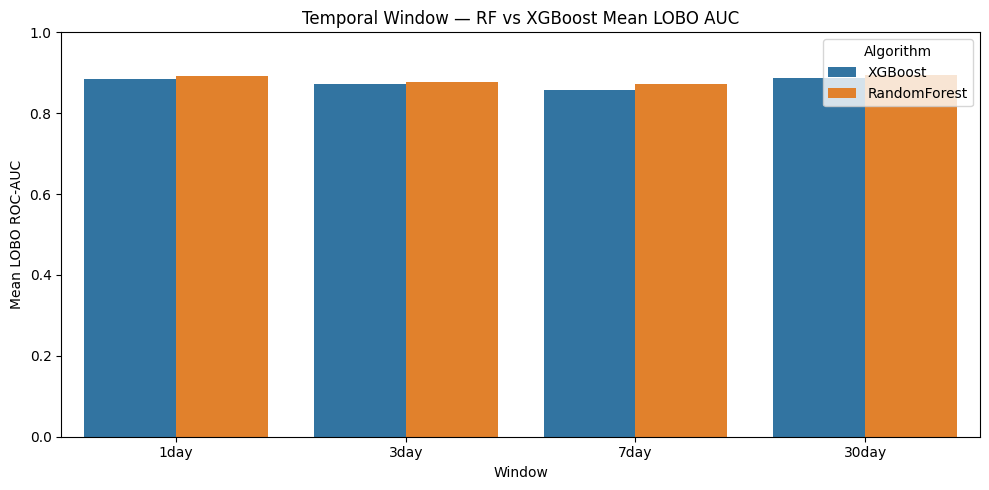

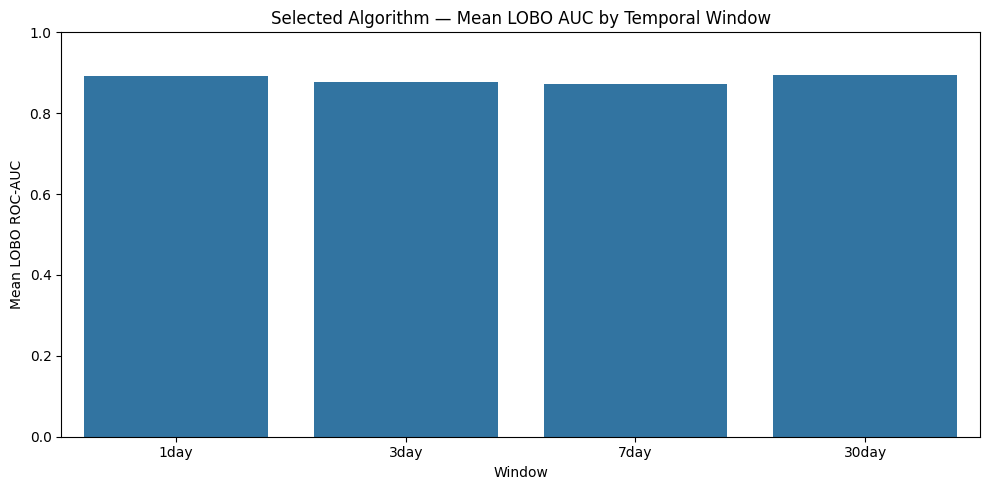

In [8]:
# ============================================================
# ALGORITHM COMPARISON FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=comparison,
    x="Window",
    y="Mean_LOBO_AUC",
    hue="Algorithm",
    ax=ax,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Mean LOBO ROC-AUC")
ax.set_title("Temporal Window — RF vs XGBoost Mean LOBO AUC")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "temporal_window_algorithm_comparison.png",
    dpi=150,
)
plt.show()


# ============================================================
# SELECTED WINDOW LOBO RESULTS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=best_summary_df,
    x="Window",
    y="Mean_LOBO_AUC",
    ax=ax,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Mean LOBO ROC-AUC")
ax.set_title("Selected Algorithm — Mean LOBO AUC by Temporal Window")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "temporal_window_selected_mean_auc.png",
    dpi=150,
)
plt.show()


## 9. LOBO ROC curves for the selected algorithm of every window

Each curve corresponds to one held-out backend.

This is the direct visual equivalent of the established Model B / Model C LOBO ROC figures.


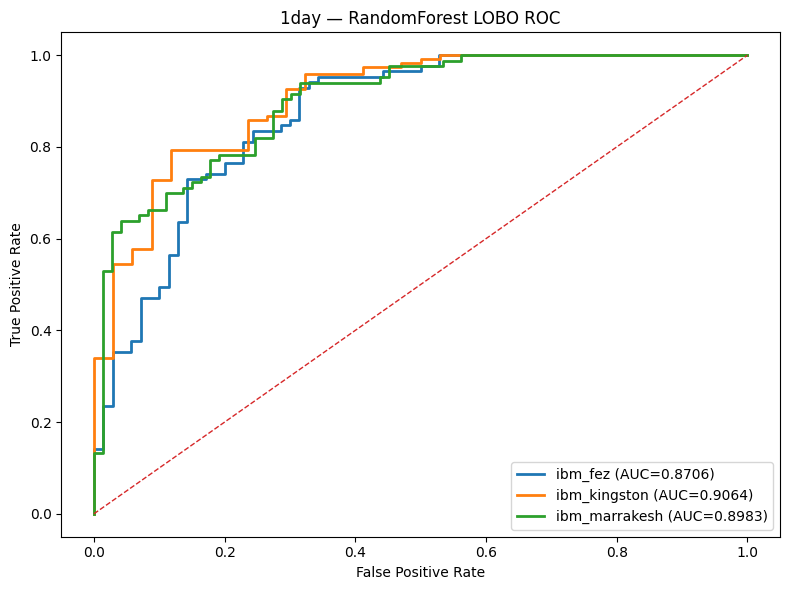

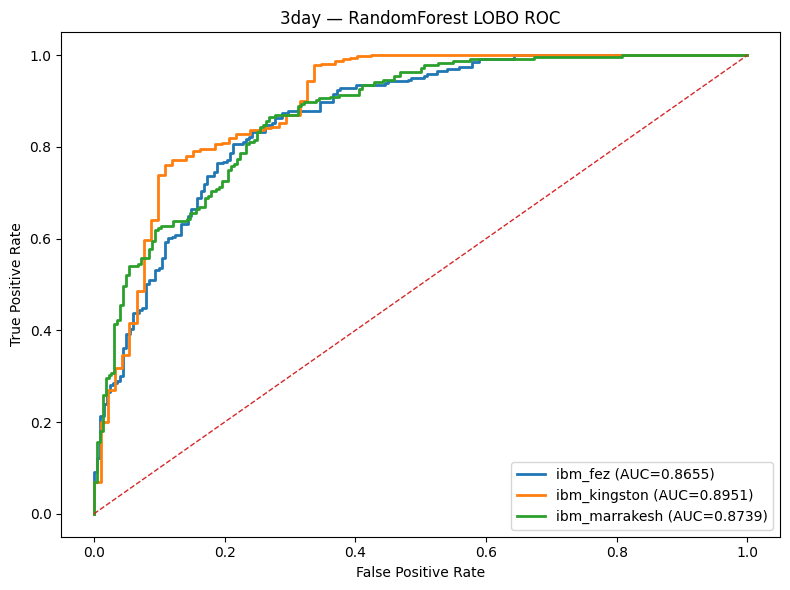

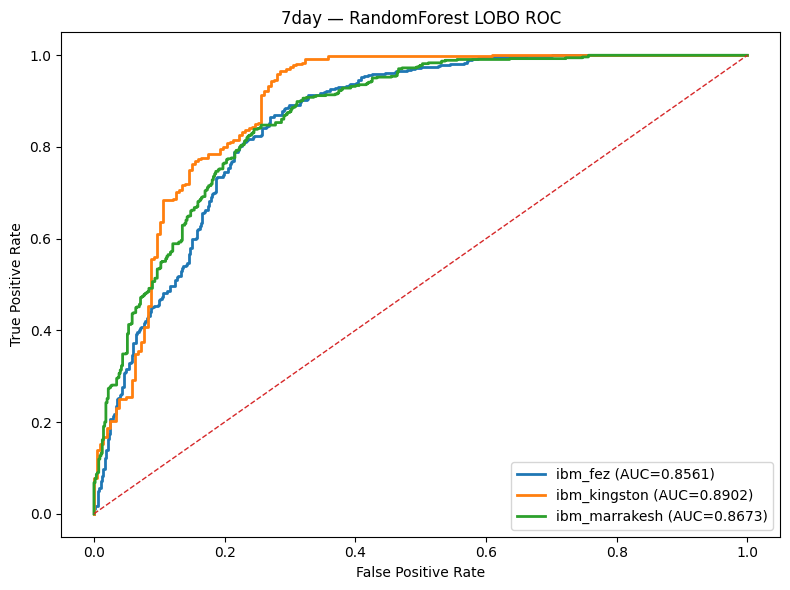

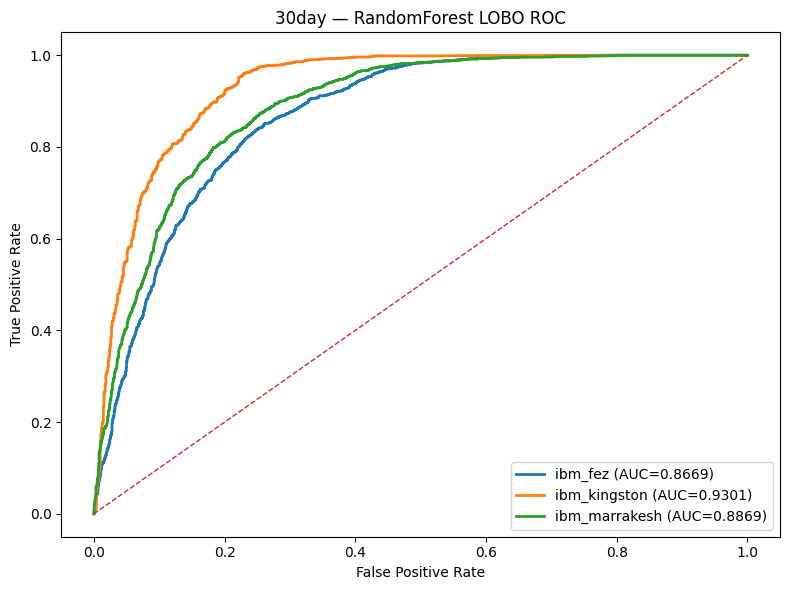

In [9]:
# ============================================================
# LOBO ROC — ONE FIGURE PER TEMPORAL WINDOW
# ============================================================

def plot_lobo_roc(result, window_label):
    fig, ax = plt.subplots(figsize=(8, 6))

    for backend, p in result["best_predictions"].items():
        fpr, tpr, _ = roc_curve(p["y_true"], p["y_prob"])
        auc = roc_auc_score(p["y_true"], p["y_prob"])
        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{backend} (AUC={auc:.4f})",
        )

    ax.plot([0, 1], [0, 1], "--", linewidth=1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(
        f"{window_label} — {result['best_name']} LOBO ROC"
    )
    ax.legend()
    plt.tight_layout()

    filename = f"{window_label}_selected_lobo_roc.png"
    plt.savefig(FIGURES_DIR / filename, dpi=150)
    plt.show()


for window_label, result in lobo_results.items():
    plot_lobo_roc(result, window_label)


## 10. Cluster-bootstrap 95% CIs for selected LOBO models

The established workflow used a 2,000-iteration cluster bootstrap over qubit IDs because repeated observations from the same physical qubit are not independent.

We preserve that procedure here for every temporal window and held-out backend.


In [10]:
# ============================================================
# CLUSTER BOOTSTRAP
# ============================================================

def cluster_bootstrap_auc(y, p, clusters, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)

    d = pd.DataFrame({
        "y": y,
        "p": p,
        "cluster": clusters,
    })

    ids = d["cluster"].unique()
    observed = roc_auc_score(y, p)
    values = []

    for _ in range(n_boot):
        sampled = rng.choice(
            ids,
            size=len(ids),
            replace=True,
        )

        pieces = [
            d[d["cluster"] == cluster]
            for cluster in sampled
        ]

        sample = pd.concat(pieces, ignore_index=True)

        if sample["y"].nunique() == 2:
            values.append(
                roc_auc_score(
                    sample["y"],
                    sample["p"],
                )
            )

    if not values:
        return observed, np.nan, np.nan

    return (
        observed,
        np.percentile(values, 2.5),
        np.percentile(values, 97.5),
    )


bootstrap_rows = []

for window_label, result in lobo_results.items():
    for backend, p in result["best_predictions"].items():
        observed, lower, upper = cluster_bootstrap_auc(
            p["y_true"],
            p["y_prob"],
            p["qubit"],
            n_boot=2000,
            seed=RANDOM_STATE,
        )

        bootstrap_rows.append({
            "Window": window_label,
            "Selected_Algorithm": result["best_name"],
            "Backend": backend,
            "Observed_AUC": observed,
            "CI_Lower_95": lower,
            "CI_Upper_95": upper,
        })

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_bootstrap_ci.csv",
    index=False,
)

display(bootstrap_df.round(4))


KeyboardInterrupt: 

In [ ]:
# ============================================================
# BOOTSTRAP FIGURE
# ============================================================

x = np.arange(len(bootstrap_df))
y = bootstrap_df["Observed_AUC"].to_numpy()
lo = bootstrap_df["CI_Lower_95"].to_numpy()
hi = bootstrap_df["CI_Upper_95"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 6))
ax.errorbar(
    x,
    y,
    yerr=[y - lo, hi - y],
    fmt="o",
    capsize=5,
)
ax.axhline(
    0.80,
    linestyle="--",
    linewidth=1,
    label="AUC = 0.80",
)
ax.set_xticks(x)
ax.set_xticklabels(
    [
        f"{r.Window}\n{r.Backend}"
        for r in bootstrap_df.itertuples()
    ],
    rotation=25,
    ha="right",
)
ax.set_ylabel("ROC-AUC")
ax.set_title(
    "Selected Temporal Models — LOBO AUC with 95% Cluster Bootstrap CI"
)
ax.legend()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "temporal_sweet_spot_bootstrap_ci.png",
    dpi=150,
)
plt.show()


## 11. Prospective prediction dates

Now the workflow changes from **evaluation** to **prediction**.

For each prediction date:

1. Build the complete historical feature timeline up to and including that date.
2. Select the requested temporal window from dates strictly before the prediction date.
3. Train the algorithm selected by LOBO for that window.
4. Predict every qubit on Sep-4 / Sep-5 / Sep-6.
5. Rank qubits independently within each backend.
6. Save the ranking CSV.

The current prediction date's T1/T2/readout error are never passed into the model features.

### Final-model rule

The four `.pkl` files saved at the end are the four models retrained through **Sep-5**, ready for the **Sep-6 prospective hardware selection**.

Sep-4 and Sep-5 models are trained in memory and only their rankings are exported.


In [ ]:
# ============================================================
# PROSPECTIVE MODEL + RANKING HELPERS
# ============================================================

def fit_selected_model(train_df, algorithm):
    if train_df["label"].nunique() < 2:
        raise ValueError(
            f"{algorithm}: training data contains only one class."
        )

    if algorithm == "XGBoost":
        model = XGBClassifier(**XGB_PARAMS)
    elif algorithm == "RandomForest":
        model = RandomForestClassifier(**RF_PARAMS)
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    model.fit(train_df[HIST_FEATURES], train_df["label"])
    return model


def make_ranking(pred_df, model, window_label, prediction_date):
    out = pred_df[
        [
            "backend",
            "qubit",
            "snapshot_date",
            "T1_us",
            "T2_us",
            "readout_error",
        ]
    ].copy()

    out["viability_score"] = model.predict_proba(
        pred_df[HIST_FEATURES]
    )[:, 1]

    out["viability_rank"] = (
        out.groupby("backend")["viability_score"]
           .rank(method="first", ascending=False)
           .astype(int)
    )

    out["label"] = pred_df["label"].astype(int).to_numpy()
    out["model_name"] = f"temporal_{window_label}"
    out["prediction_date"] = prediction_date
    out["training_window_days"] = WINDOWS[window_label]

    out = out[
        [
            "model_name",
            "training_window_days",
            "prediction_date",
            "backend",
            "qubit",
            "viability_score",
            "viability_rank",
            "label",
            "T1_us",
            "T2_us",
            "readout_error",
            "snapshot_date",
        ]
    ]

    return (
        out.sort_values(["backend", "viability_rank"])
           .reset_index(drop=True)
    )


In [ ]:
# ============================================================
# GENERATE SEP-4 / SEP-5 / SEP-6 PREDICTIONS
# ============================================================

prospective_rankings = []
prospective_summary = []

for prediction_date in PREDICTION_DATES:
    print("\n" + "=" * 80)
    print("PREDICTION DATE:", prediction_date)
    print("=" * 80)

    pred = prediction_rows(featured, prediction_date)

    for window_label, window_days in WINDOWS.items():
        train, dates_used = select_window(
            featured,
            prediction_date,
            window_days,
        )

        selected_algorithm = lobo_results[window_label]["best_name"]
        model = fit_selected_model(
            train,
            selected_algorithm,
        )

        ranking = make_ranking(
            pred,
            model,
            window_label,
            prediction_date,
        )

        prospective_rankings.append(ranking)

        csv_path = (
            RESULTS_DIR
            / f"temporal_{window_label}_predictions_{prediction_date}.csv"
        )
        ranking.to_csv(csv_path, index=False)

        prospective_summary.append({
            "prediction_date": prediction_date,
            "window": window_label,
            "training_dates": f"{dates_used[0]} → {dates_used[-1]}",
            "training_observed_dates": len(dates_used),
            "training_rows": len(train),
            "training_viable_rate": train["label"].mean(),
            "selected_algorithm": selected_algorithm,
            "prediction_rows": len(ranking),
            "ranking_csv": str(csv_path),
        })

        print(
            f"{window_label:>6} | "
            f"{selected_algorithm:<12} | "
            f"train={dates_used[0]} → {dates_used[-1]} | "
            f"rows={len(train):,} | "
            f"saved={csv_path.name}"
        )

prospective_summary_df = pd.DataFrame(prospective_summary)
prospective_summary_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_prospective_summary.csv",
    index=False,
)

all_predictions_df = pd.concat(
    prospective_rankings,
    ignore_index=True,
)

all_predictions_df.to_csv(
    RESULTS_DIR / "temporal_sweet_spot_all_predictions.csv",
    index=False,
)

print("\nProspective ranking generation complete.")
display(prospective_summary_df)


## 12. Save the four final Sep-6 models

Only four final `.pkl` artifacts are created:

```text
models/temporal_sweet_spot/
    temporal_1day_final_sep6.pkl
    temporal_3day_final_sep6.pkl
    temporal_7day_final_sep6.pkl
    temporal_30day_final_sep6.pkl
```

These are the four models that can be used by the separate hardware experiment.

The Sep-4 and Sep-5 model instances are intentionally not saved as separate `.pkl` files, preventing the directory from filling with date × window duplicates.


In [ ]:
# ============================================================
# FINAL SEP-6 MODELS — ONLY FOUR PICKLE FILES
# ============================================================

final_model_metadata = []

SEP6_DATE = pd.Timestamp("2026-09-06").date()

for window_label, window_days in WINDOWS.items():
    train, dates_used = select_window(
        featured,
        SEP6_DATE,
        window_days,
    )

    selected_algorithm = lobo_results[window_label]["best_name"]

    model = fit_selected_model(
        train,
        selected_algorithm,
    )

    filename = f"temporal_{window_label}_final_sep6.pkl"
    model_path = MODELS_DIR / filename

    with open(model_path, "wb") as f:
        pickle.dump(model, f)

    lobo = lobo_results[window_label]["best_results"]

    metadata = {
        "model_name": f"Temporal_{window_label}",
        "model_file": filename,
        "selected_algorithm": selected_algorithm,
        "selection_rule": "highest_mean_LOBO_AUC",
        "prediction_date": str(SEP6_DATE),
        "training_start": str(dates_used[0]),
        "training_end": str(dates_used[-1]),
        "training_observed_dates": len(dates_used),
        "training_rows": int(len(train)),
        "training_viable_rate": float(train["label"].mean()),
        "backends": sorted(train["backend"].unique().tolist()),
        "n_features": len(HIST_FEATURES),
        "features": HIST_FEATURES,
        "label_thresholds": {
            "T1_us": T1_THRESH,
            "T2_us": T2_THRESH,
            "readout_error": RE_THRESH,
        },
        "feature_source": "prior_sessions_only_shift_expand",
        "leakage_status": "NONE_VERIFIED_BY_AUDIT",
        "model_parameters": (
            XGB_PARAMS if selected_algorithm == "XGBoost"
            else RF_PARAMS
        ),
        "lobo_results": lobo.round(6).to_dict(orient="records"),
        "lobo_mean_auc": float(lobo["AUC"].mean()),
        "lobo_min_auc": float(lobo["AUC"].min()),
    }

    metadata_path = RESULTS_DIR / (
        f"temporal_{window_label}_final_sep6_metadata.json"
    )

    with open(metadata_path, "w", encoding="utf-8") as f:
        json.dump(metadata, f, indent=2)

    final_model_metadata.append(metadata)

final_models_df = pd.DataFrame(final_model_metadata)

final_models_df[
    [
        "model_name",
        "selected_algorithm",
        "training_start",
        "training_end",
        "training_rows",
        "lobo_mean_auc",
        "lobo_min_auc",
    ]
].to_csv(
    RESULTS_DIR / "temporal_sweet_spot_final_model_summary.csv",
    index=False,
)

display(
    final_models_df[
        [
            "model_name",
            "selected_algorithm",
            "training_start",
            "training_end",
            "training_rows",
            "lobo_mean_auc",
            "lobo_min_auc",
        ]
    ].round(4)
)


## 13. Sep-6 predicted-qubit tables

These are the rankings to inspect before moving to `ibm_circuits`.

The model ranks **within each backend**, so rank 1 is the highest predicted viability qubit for that backend under that temporal model.


In [ ]:
# ============================================================
# SEP-6 TOP RANKINGS
# ============================================================

sep6_predictions = all_predictions_df[
    all_predictions_df["prediction_date"] == SEP6_DATE
].copy()

for window_label in WINDOWS:
    print("\n" + "=" * 70)
    print(f"TEMPORAL {window_label} — SEP-6")
    print("=" * 70)

    display(
        sep6_predictions[
            sep6_predictions["model_name"] == f"temporal_{window_label}"
        ]
        .sort_values(["backend", "viability_rank"])
        .groupby("backend", group_keys=False)
        .head(10)
        [
            [
                "backend",
                "qubit",
                "viability_score",
                "viability_rank",
                "T1_us",
                "T2_us",
                "readout_error",
            ]
        ]
    )


## 14. Hardware-selection exports

The separate `ibm_circuits` project can consume these files.

The most useful Sep-6 files are:

- `sep6_all_temporal_model_predictions.csv`
- `sep6_all_temporal_models_top10_per_backend.csv`

These contain the predictions from the four temporal models.

**Do not simply take ranks 1, 2, and 3 as a GHZ triplet.** The hardware project must select the highest-ranked **topology-valid connected 3-qubit group** for each model/backend.


In [ ]:
# ============================================================
# HARDWARE INPUT FILES
# ============================================================

HARDWARE_DIR = RESULTS_DIR / "hardware_selection"
HARDWARE_DIR.mkdir(parents=True, exist_ok=True)

# All Sep-6 temporal predictions.
sep6_all_path = HARDWARE_DIR / "sep6_all_temporal_model_predictions.csv"
sep6_predictions.sort_values(
    ["model_name", "backend", "viability_rank"]
).to_csv(sep6_all_path, index=False)

# Top 10 per backend per model.
sep6_top10 = (
    sep6_predictions
    .sort_values(["model_name", "backend", "viability_rank"])
    .groupby(["model_name", "backend"], group_keys=False)
    .head(10)
    .reset_index(drop=True)
)

sep6_top10_path = HARDWARE_DIR / "sep6_all_temporal_models_top10_per_backend.csv"
sep6_top10.to_csv(sep6_top10_path, index=False)

# One top-ranked qubit per backend per model.
sep6_top1 = (
    sep6_predictions
    .sort_values(["model_name", "backend", "viability_rank"])
    .groupby(["model_name", "backend"], group_keys=False)
    .head(1)
    .reset_index(drop=True)
)

sep6_top1_path = HARDWARE_DIR / "sep6_all_temporal_models_top1_per_backend.csv"
sep6_top1.to_csv(sep6_top1_path, index=False)

print("Sep-6 all predictions:", sep6_all_path)
print("Sep-6 top 10:", sep6_top10_path)
print("Sep-6 top 1:", sep6_top1_path)

display(
    sep6_top1[
        [
            "model_name",
            "backend",
            "qubit",
            "viability_score",
            "viability_rank",
        ]
    ].sort_values(["backend", "model_name"])
)


## 15. Sep-4 / Sep-5 / Sep-6 selection stability

This shows whether the same physical qubits remain highly ranked across the three prospective dates.

It is a descriptive stability analysis only; it does not replace the hardware validation.


In [ ]:
# ============================================================
# TOP-10 JACCARD STABILITY ACROSS SEP-4 / SEP-5 / SEP-6
# ============================================================

def top10_set(df, model_name, backend, prediction_date):
    x = df[
        (df["model_name"] == model_name)
        & (df["backend"] == backend)
        & (df["prediction_date"] == prediction_date)
    ].sort_values("viability_rank").head(10)

    return set(x["qubit"].astype(int))


stability_rows = []

for window_label in WINDOWS:
    model_name = f"temporal_{window_label}"

    for backend in sorted(sep6_predictions["backend"].unique()):
        sets = {
            d: top10_set(
                all_predictions_df,
                model_name,
                backend,
                d,
            )
            for d in PREDICTION_DATES
        }

        for d1, d2 in [
            (PREDICTION_DATES[0], PREDICTION_DATES[1]),
            (PREDICTION_DATES[1], PREDICTION_DATES[2]),
            (PREDICTION_DATES[0], PREDICTION_DATES[2]),
        ]:
            inter = len(sets[d1] & sets[d2])
            union = len(sets[d1] | sets[d2])

            stability_rows.append({
                "model": model_name,
                "backend": backend,
                "date_1": d1,
                "date_2": d2,
                "top10_intersection": inter,
                "top10_jaccard": inter / union if union else np.nan,
            })

stability_df = pd.DataFrame(stability_rows)
stability_df.to_csv(
    RESULTS_DIR / "sep4_sep5_sep6_top10_stability.csv",
    index=False,
)

display(stability_df.round(4))


## 16. Final integrity checks

Before using any Sep-6 ranking for hardware, all checks below must pass.

- Exactly four temporal windows were evaluated.
- Each window evaluated all three LOBO folds.
- Each window has a selected algorithm.
- Sep-4, Sep-5, Sep-6 rankings exist.
- No duplicate backend/qubit/model/date ranking rows.
- Exactly four final Sep-6 pickle files are created by this notebook.
- Existing Model A/B/C files are untouched.


In [ ]:
# ============================================================
# FINAL INTEGRITY CHECKS
# ============================================================

assert set(WINDOWS.keys()) == {"1day", "3day", "7day", "30day"}

for window_label in WINDOWS:
    result = lobo_results[window_label]
    assert set(result["best_results"]["Test_Backend"]) == BACKEND_EXPECTED
    assert result["best_name"] in {"XGBoost", "RandomForest"}

assert set(all_predictions_df["prediction_date"]) == set(PREDICTION_DATES)

duplicates = all_predictions_df.duplicated(
    subset=[
        "model_name",
        "prediction_date",
        "backend",
        "qubit",
    ]
).sum()
assert duplicates == 0, f"Duplicate prediction rows: {duplicates}"

final_pickle_files = sorted(
    MODELS_DIR.glob("temporal_*_final_sep6.pkl")
)

assert len(final_pickle_files) == 4, (
    f"Expected exactly 4 final temporal model files, "
    f"found {len(final_pickle_files)}"
)

for feature in HIST_FEATURES:
    assert feature not in {"T1_us", "T2_us", "readout_error"}

print("=" * 80)
print("ALL FINAL INTEGRITY CHECKS PASSED")
print("=" * 80)
print("\nFinal temporal models:")
for p in final_pickle_files:
    print(" ", p.name)

print("\nSep-6 hardware input:")
print(" ", sep6_all_path)
print(" ", sep6_top10_path)


# Final output map

```text
results/
└── temporal_sweet_spot/
    ├── temporal_sweet_spot_lobo_all_results.csv
    ├── temporal_sweet_spot_algorithm_comparison.csv
    ├── temporal_sweet_spot_selected_window_summary.csv
    ├── temporal_sweet_spot_bootstrap_ci.csv
    ├── temporal_sweet_spot_prospective_summary.csv
    ├── temporal_sweet_spot_all_predictions.csv
    ├── temporal_1day_predictions_2026-09-04.csv
    ├── temporal_3day_predictions_2026-09-04.csv
    ├── ...
    ├── temporal_30day_predictions_2026-09-06.csv
    ├── temporal_1day_final_sep6_metadata.json
    ├── ...
    ├── temporal_30day_final_sep6_metadata.json
    ├── sep4_sep5_sep6_top10_stability.csv
    │
    ├── figures/
    │   ├── temporal_window_algorithm_comparison.png
    │   ├── temporal_window_selected_mean_auc.png
    │   ├── 1day_selected_lobo_roc.png
    │   ├── 3day_selected_lobo_roc.png
    │   ├── 7day_selected_lobo_roc.png
    │   ├── 30day_selected_lobo_roc.png
    │   └── temporal_sweet_spot_bootstrap_ci.png
    │
    └── hardware_selection/
        ├── sep6_all_temporal_model_predictions.csv
        ├── sep6_all_temporal_models_top10_per_backend.csv
        └── sep6_all_temporal_models_top1_per_backend.csv

models/
└── temporal_sweet_spot/
    ├── temporal_1day_final_sep6.pkl
    ├── temporal_3day_final_sep6.pkl
    ├── temporal_7day_final_sep6.pkl
    └── temporal_30day_final_sep6.pkl
```

### Next stage

Do not submit a QPU job from this notebook.

First inspect the Sep-6 temporal rankings together with the existing Model A/B/C Sep-6 rankings. Then the separate `ibm_circuits` workflow should:

1. validate coupling/topology,
2. select the highest-ranked valid 3-qubit group for each model/backend,
3. run the **same** GHZ workload, shots, and transpilation procedure,
4. record fidelity and hardware metadata,
5. compare temporal-window selection against Model A/B/C and the random controls.
